In [1]:
import os, json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import norm
from src import Questions


plt.rcParams.update({'font.size': 14})

In [2]:
# creating a dataframe of all of the annotator profiles
EXCLUDED_SCORES = ["2_13", "23_", "24_", "25_", "27_"]
EXCLUDED_WHOLE = [23, 24, 25, 27]
questions = Questions().get_questions()
SCORED_ANNOTATOR_DIR = "annotation_artefacts/final_annotator_objects"
os.makedirs(SCORED_ANNOTATOR_DIR, exist_ok=True)


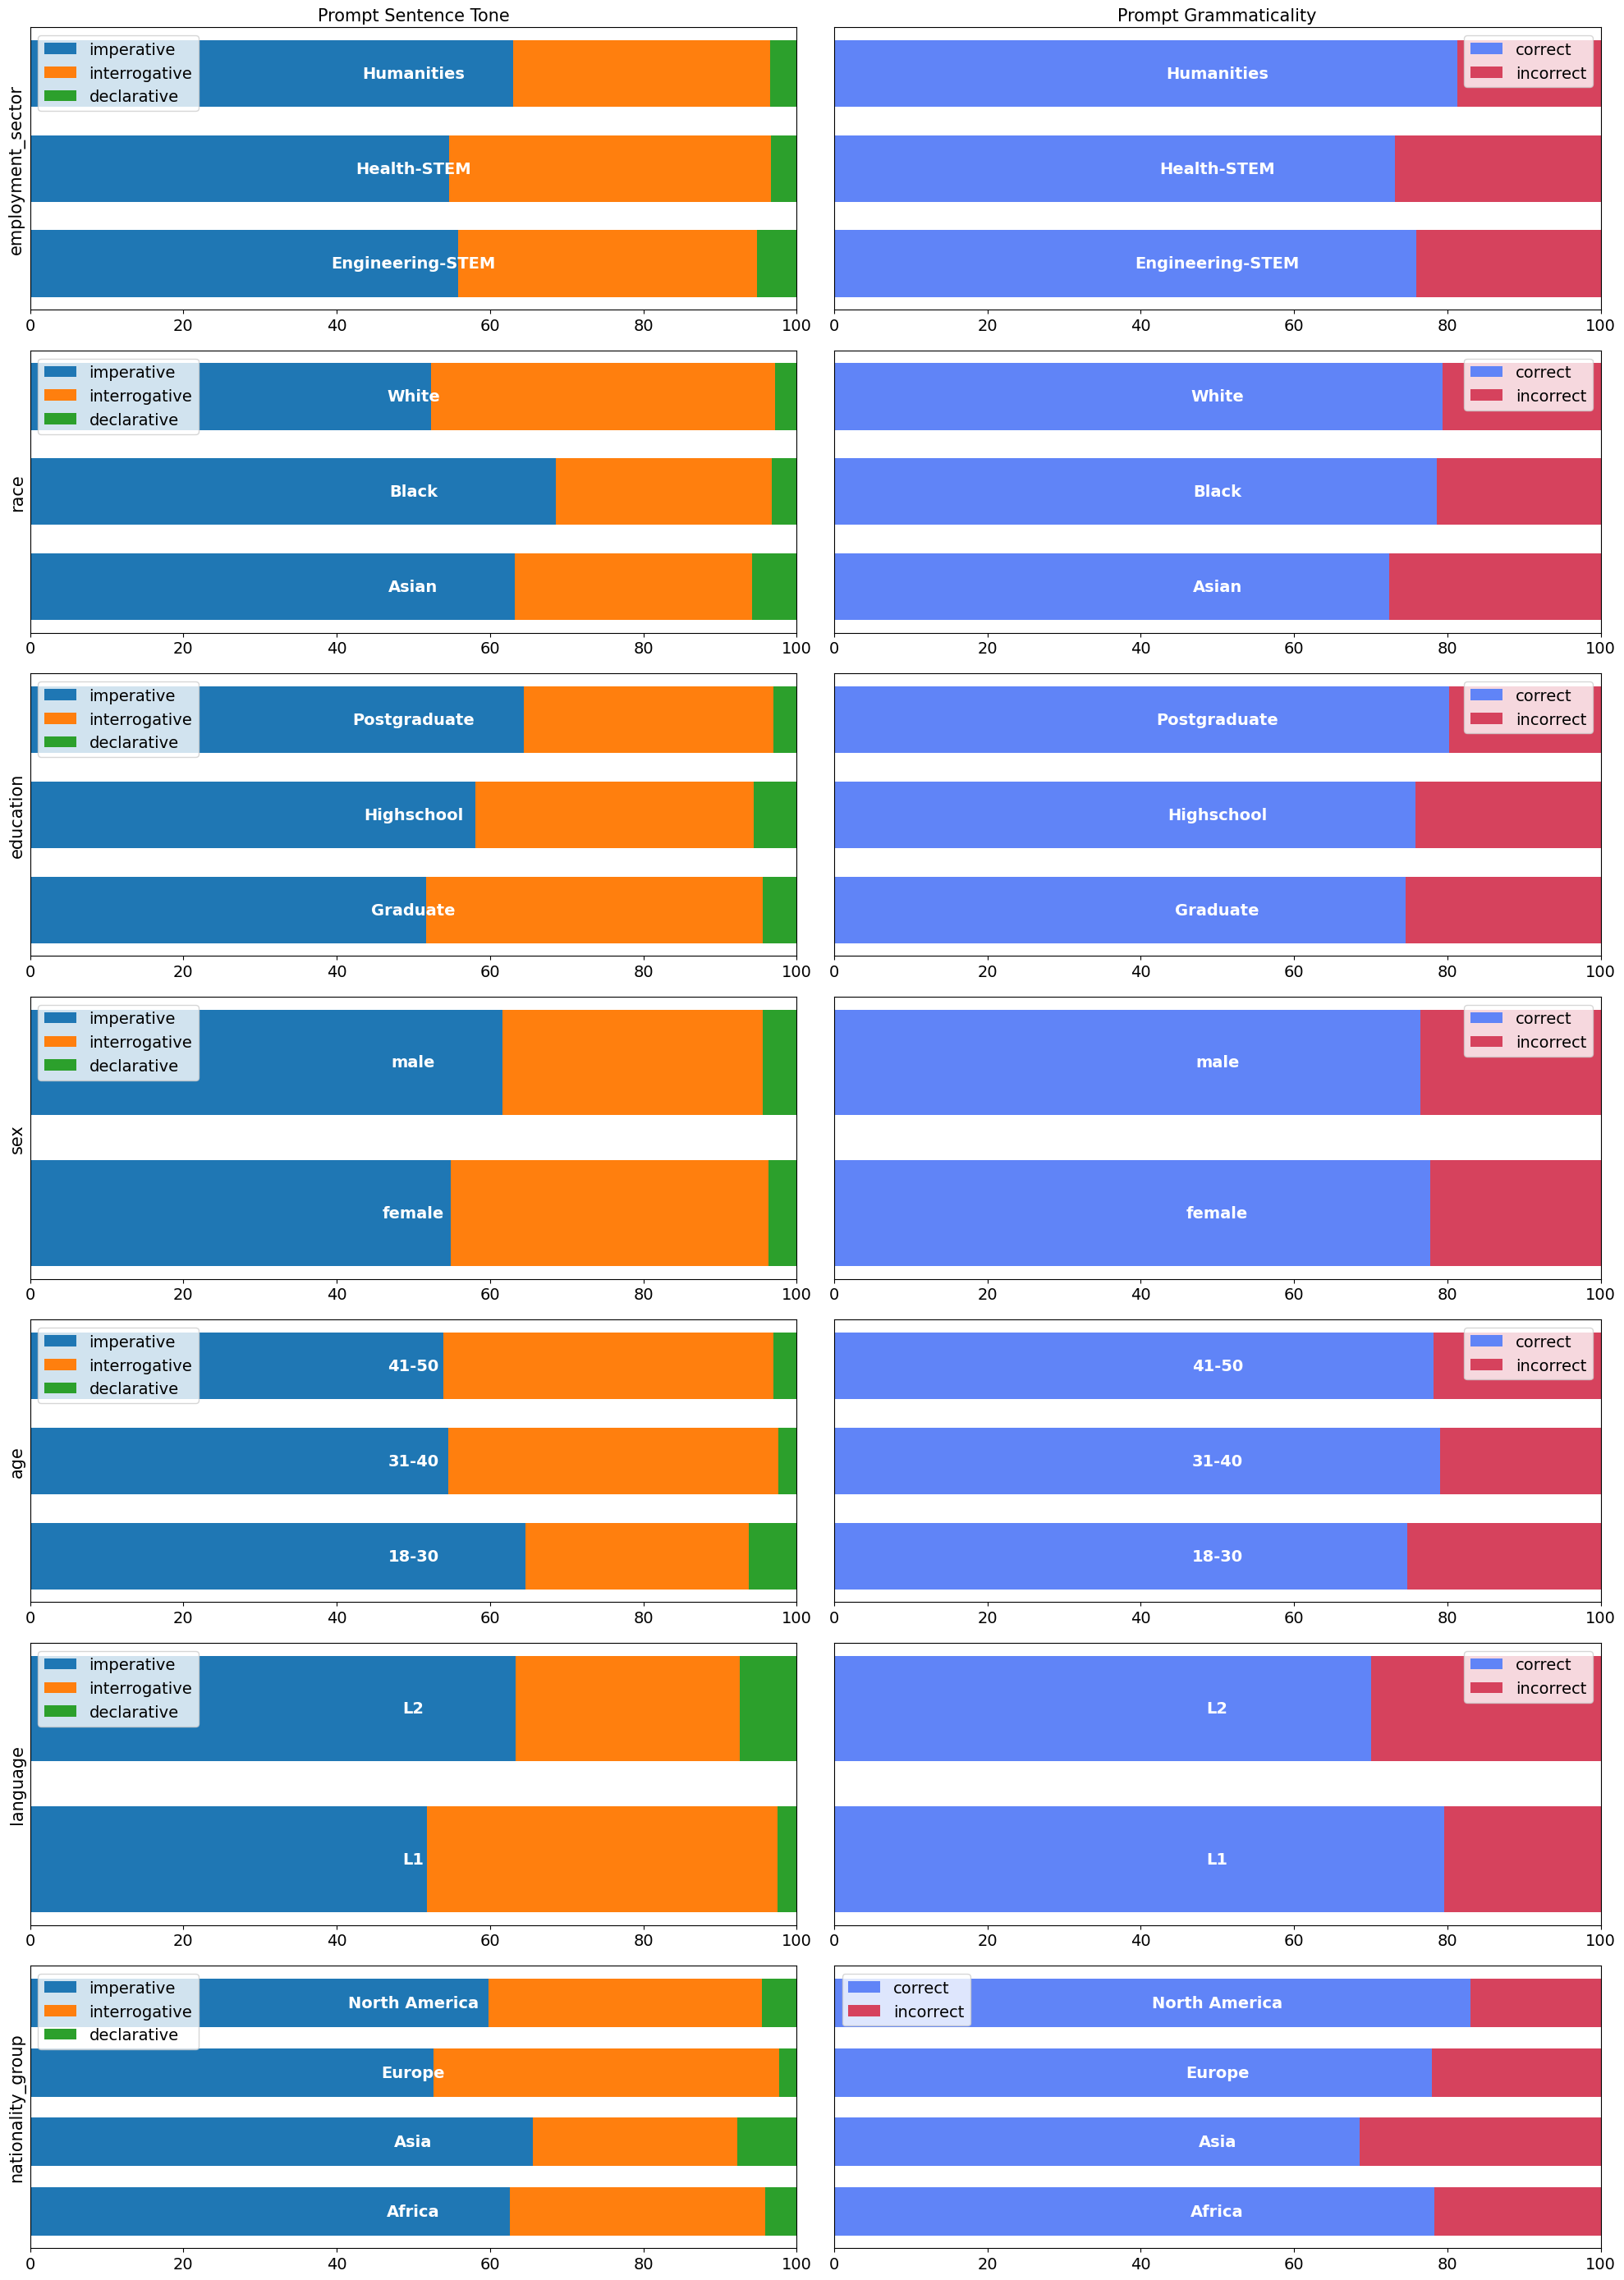

In [4]:
from src.utils.viz_utils import plot_histogram_by_category, plot_grouped_bar_chart, plot_stacked_bar_chart

# making a df that has info: sum sentence length, freq count for each of the annotators
df_ptype_freqtable = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)
    
    prompt_lengths = []
    prompt_tone_freq_table = {
        "imperative" : 0,
        "interrogative" : 0,
        "declarative" : 0,
    }
    prompt_grammar_freq_table = {
        "correct" : 0,
        "incorrect" : 0,
    }
    
    for i, (question, v) in enumerate(annotator_object["answers"].items()):
        if i not in EXCLUDED_WHOLE :
            if v["answer"]:
                prompt_lengths.append(v["sentence_length"])
                prompt_tone_freq_table[v["sentence_type"]] += 1
                prompt_grammar_freq_table[v["grammaticality"]] += 1

    df_ptype_freqtable.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        "sum_prompt_lengths" : sum(prompt_lengths),
        **prompt_tone_freq_table,
        **prompt_grammar_freq_table
    })

df_ptype_freqtable = sorted(df_ptype_freqtable, key=lambda x: x["id"])
df_ptype_freqtable = pd.DataFrame(df_ptype_freqtable)


aggregates = {}
PROFILE_COLUMNS = ["employment_sector", "race", "education", "sex", "age", "language", "nationality_group"]
for pc in PROFILE_COLUMNS:
    aggregates[pc] = {}
    for demo_label_name, group_df in df_ptype_freqtable.groupby(pc):
        # implementing exceptions
        if pc == "employment_sector":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "education":
            group = group_df[group_df["language"] == "L1"]
        elif pc == "sex":
            group = group_df[group_df["language"] == "L1"]
            
        elif(demo_label_name == "Black"):
            group = group_df[group_df["language"] == "L1"]
        elif(demo_label_name == "White"):
            group = group_df[group_df["language"] == "L1"]
        # implementing exceptions
        demo_label_plengths = group_df["sum_prompt_lengths"].to_list()
        
        tone_ftable = group_df[['imperative', 'interrogative', 'declarative']]
        tone_sums = tone_ftable.sum().to_dict()

        grammar_ftable = group_df[['correct', 'incorrect']]
        grammar_sums = grammar_ftable.sum().to_dict()

        group_stats = {
            "Prompt Lengths" : demo_label_plengths,
            "Prompt Tone" : tone_sums,
            "Prompt Grammar" : grammar_sums,
        }

        aggregates[pc][demo_label_name] = group_stats
# # visualizing
N = len(PROFILE_COLUMNS)
fig, axes = plt.subplots(N, 2, figsize=(20, 4 * N))

LABELSIZE=15

# Column labels
# column_labels = ['Sentence Length Histogram', 'Prompt Sentence Tone', 'Prompt Grammaticality']
column_labels = ['Prompt Sentence Tone', 'Prompt Grammaticality']
for col, label in enumerate(column_labels):
    axes[0, col].set_title(label, fontsize=LABELSIZE)

# Row labels
for row, label in enumerate(PROFILE_COLUMNS):
    axes[row, 0].set_ylabel(label, fontsize=LABELSIZE, rotation=90)

nrows, ncols = axes.shape
for i, j in np.ndindex(nrows, ncols):
    ax = axes[i, j]
    demo_profile = PROFILE_COLUMNS[i]
    demo_data = aggregates[demo_profile]
    # if j == 0:
    #     data = {k : v["Prompt Lengths"] for k, v in demo_data.items()}
    #     plot_histogram_by_category(data, ax)
    if j == 0:
        data = {k : v["Prompt Tone"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)
    else:
        data = {k : v["Prompt Grammar"] for k, v in demo_data.items()}
        plot_stacked_bar_chart(data, ax, height=0.7)

plt.tight_layout()
plt.show()

In [19]:

df_list = []
for annfilename in os.listdir(SCORED_ANNOTATOR_DIR):
    annotator_filepath = os.path.join(SCORED_ANNOTATOR_DIR, annfilename)
    with open(annotator_filepath, "r") as  ao:
        annotator_object = json.load(ao)

    task_group_stats = {}
    task_types = ['mt_and_summarization', 'syntaxes', 'knowledge_and_reasoning', 'semantics', 'qa_extraction']
    for tt in task_types:
        prompt_lengths = []
        prompt_type_freq_table = {
            f"{tt}-imperative" : 0,
            f"{tt}-interrogative" : 0,
            f"{tt}-declarative" : 0,
        }
        prompt_grammaticality = {
            f"{tt}-grammar_correct" : 0,
            f"{tt}-grammar_incorrect" : 0,
        }
        for qi, (q, v) in enumerate(annotator_object["answers"].items()):
            if qi not in EXCLUDED_WHOLE:
                if v["answer"] and questions[q]['question_type'] == tt:
                    prompt_lengths.append(v["sentence_length"])
                    prompt_type_freq_table[f"{tt}-{v["sentence_type"]}"] += 1
                    prompt_grammaticality[f"{tt}-grammar_{v["grammaticality"]}"] += 1
        
        task_group_stats[f"{tt}-avg_sentence_lengths"] = sum(prompt_lengths)/len(prompt_lengths) if len(prompt_lengths) > 0 else 0
        task_group_stats.update(prompt_type_freq_table)
        task_group_stats.update(prompt_grammaticality)

    df_list.append({
        "id" : annotator_object["id"],
        **annotator_object["profile"],
        **task_group_stats
    })

df_list = sorted(df_list, key=lambda x: x["id"])
df = pd.DataFrame(df_list)

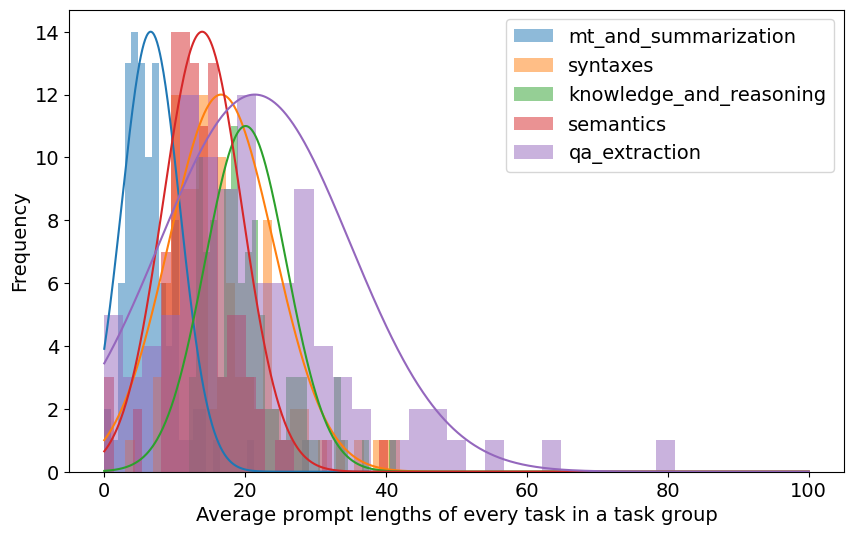

In [20]:
# for prompt length make histogram of 5 task types overlay each other
cols = df.columns[df.columns.str.contains("avg_sentence_lengths")]
plt.figure(figsize=(10, 6))

for col in cols:
    values = df[col].dropna()
    counts, bin_edges, _ = plt.hist(values, bins=30, alpha=0.5, label=col.replace("-avg_sentence_lengths", "").strip())

    mu, std = np.mean(values), np.std(values)
    x = np.linspace(0, 100, 1000)
    p = norm.pdf(x, mu, std)
    scale = max(counts) / np.max(p)

    # Get the current color used for the histogram
    color = plt.gca().patches[-1].get_facecolor()
    plt.plot(x, p * scale, color=color, alpha=1)

plt.legend()
plt.xlabel('Average prompt lengths of every task in a task group')
plt.ylabel('Frequency')
plt.show()

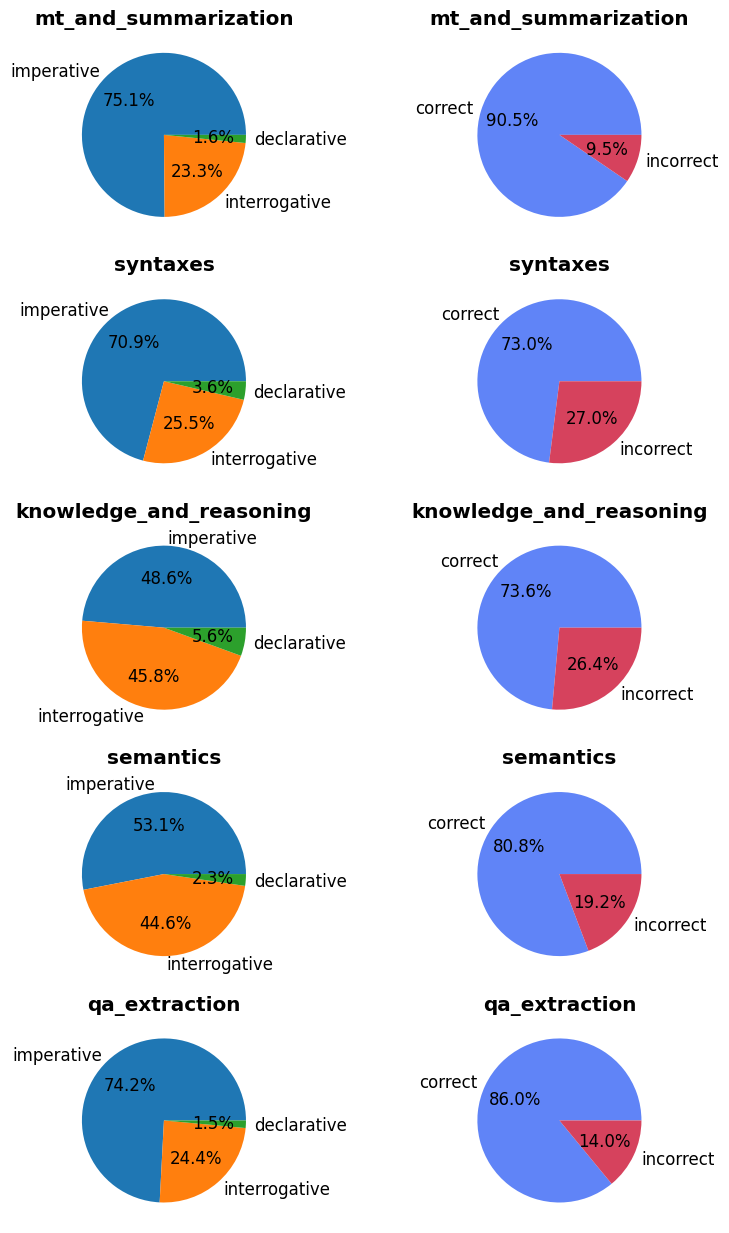

In [21]:
plt.rcParams.update({'font.size': 12})

# Grammar pie chart setup
colors1 = ['#6084f7', '#d6425d']
keywords1 = ["grammar_correct", "grammar_incorrect"]
pattern1 = "|".join(keywords1)
cols1 = df.columns[df.columns.str.contains(pattern1)]
s1 = df[cols1].sum(axis=0)

grouped1 = {}
for k, v in s1.items():
    prefix, label = k.split('-', 1)
    grouped1.setdefault(prefix, {})[label] = v

# Sentence type pie chart setup
colors2 = ['#1f77b4', '#ff7f0e', '#2ca02c']
keywords2 = ["imperative", "interrogative", "declarative"]
pattern2 = "|".join(keywords2)
cols2 = df.columns[df.columns.str.contains(pattern2)]
s2 = df[cols2].sum(axis=0)

grouped2 = {}
for k, v in s2.items():
    prefix, label = k.split('-', 1)
    grouped2.setdefault(prefix, {})[label] = v

# Ensure same number of rows (fill shorter one with None)
g1_items = list(grouped1.items())
g2_items = list(grouped2.items())
max_rows = max(len(g1_items), len(g2_items))

while len(g1_items) < max_rows:
    g1_items.append((None, None))
while len(g2_items) < max_rows:
    g2_items.append((None, None))

# Create subplot grid: rows = max_rows, cols = 2
fig, axes = plt.subplots(max_rows, 2, figsize=(8, 2.5 * max_rows))

for row in range(max_rows):
    # Grammar pie chart (left column)
    prefix, data = g1_items[row]
    ax = axes[row][1]
    if prefix is not None:
        ax.pie(data.values(), labels=[k.replace("grammar_", "") for k in data.keys()],
               autopct='%1.1f%%', colors=colors1)
        ax.set_title(prefix, fontweight='bold')
    else:
        ax.axis('off')

    # Sentence type pie chart (right column)
    prefix, data = g2_items[row]
    ax = axes[row][0]
    if prefix is not None:
        ax.pie(data.values(), labels=data.keys(),
               autopct='%1.1f%%', colors=colors2)
        ax.set_title(prefix, fontweight='bold')
    else:
        ax.axis('off')

plt.tight_layout()
plt.show()


In [22]:
import json
import pandas as pd

INST_TUNING_CLASSIF_DS = "inst_tuning_analysis/openhermes2_5_sample.csv"
INST_TUNING_CLASSIF_HISTORY = "inst_tuning_analysis/inst_tuning_analysis/history-inst_tuning_analysis.json"
history_file = json.load(open(INST_TUNING_CLASSIF_HISTORY, "r"))

public_inst_df = pd.read_csv(INST_TUNING_CLASSIF_DS)[["source", "instruction"]]

In [23]:
tone_answers = []
for msg in history_file['tone_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    tone_answers.append(answer)


grammar_answer = []
for msg in history_file['grammar_classification-chatgpt_4o_latest']['messages']:
    answer = msg['chat_history'][1]["content"].lower()
    grammar_answer.append(answer)

public_inst_df['tone'] = tone_answers
public_inst_df['grammaticality'] = grammar_answer

In [24]:
public_inst_df

,source,instruction,tone,grammaticality
0,CamelAI,A group of 100 patients were treated for a par...,declarative,correct
1,CamelAI,"""How can molecular dynamics simulations be use...",interrogative,correct
2,CamelAI,A radioactive element has a half-life of 30 ye...,interrogative,correct
3,CamelAI,What is the value of Euler's totient function ...,interrogative,correct
4,CamelAI,A manufacturer wants to produce a composite ma...,imperative,correct
...,...,...,...,...
1395,platypus,"The complex number $z$ is equal to $9 + bi$, w...",declarative,correct
1396,platypus,"In the diagram, $\triangle XYZ$ is right-angle...",imperative,correct
1397,platypus,"Last year, a woman was able to demonstrate tha...",declarative,correct
1398,platypus,"If $\sqrt{5 + x} + \sqrt{20 - x} = 7$, what is...",interrogative,correct


In [25]:
full_data = {}
for groupname, group in public_inst_df.groupby("source"):
    full_data[groupname] = {
        "tone" : group['tone'].value_counts().to_dict(),
        "grammaticality" : group['grammaticality'].value_counts().to_dict(),
    }


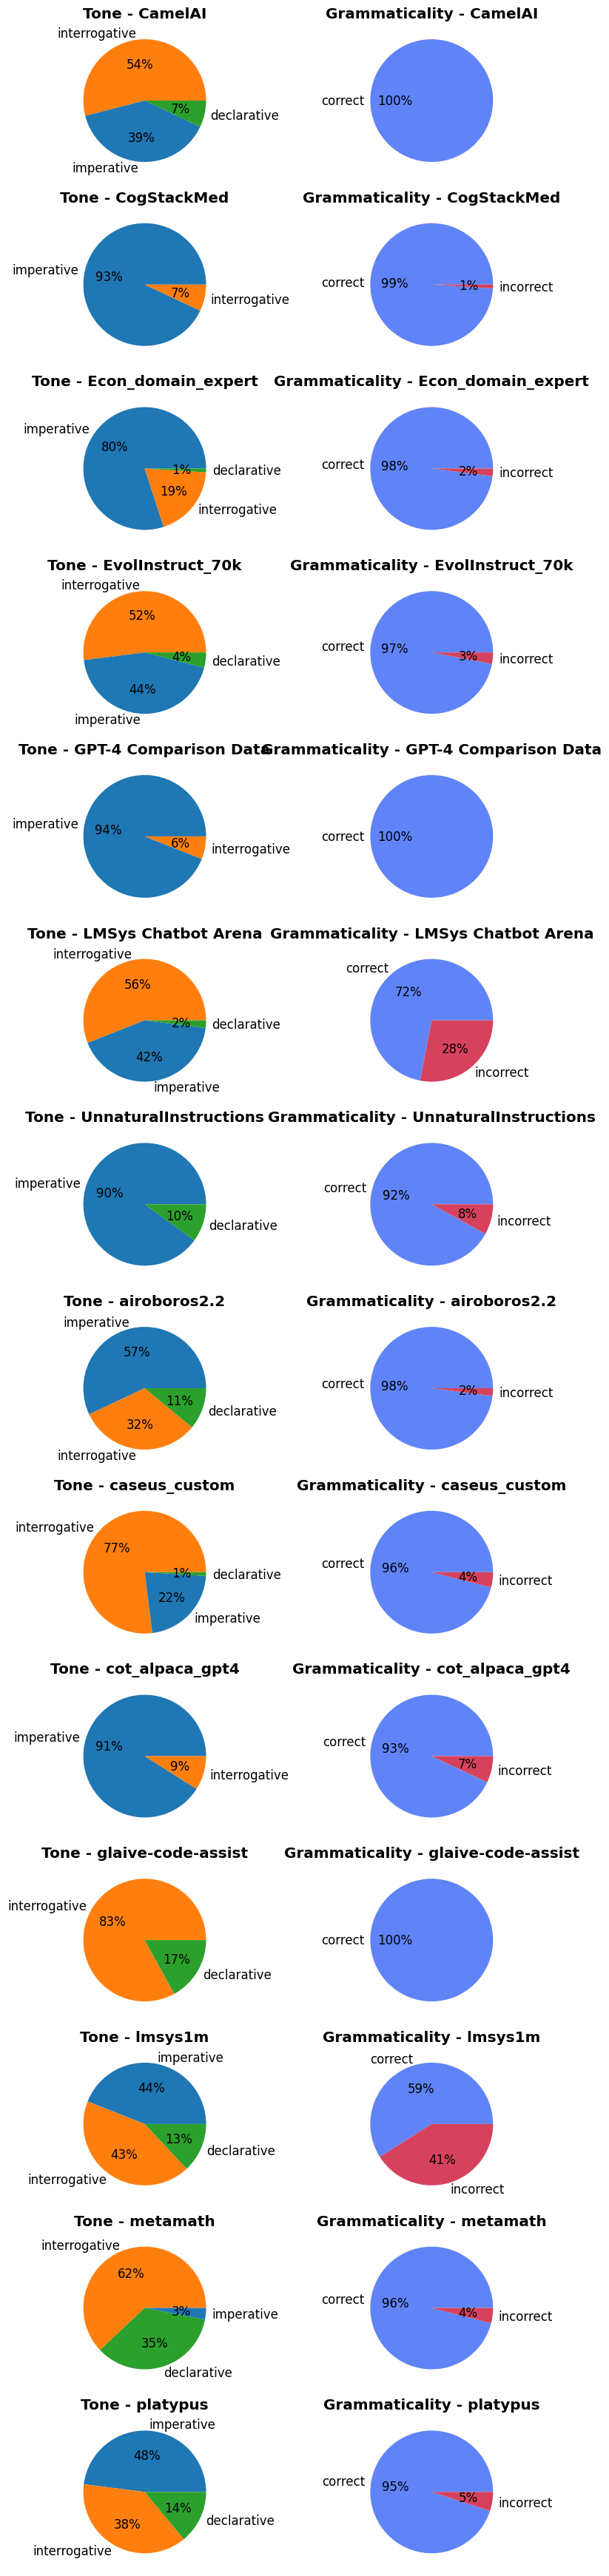

In [26]:
color_dict = {
    "imperative" : "#1f77b4",
    "interrogative" : "#ff7f0e",
    "declarative" : "#2ca02c",
    "correct" : "#6084f7",
    "incorrect" : "#d6425d",
}

#  Sort keys to make consistent grid layout
keys = sorted(full_data.keys())
n = len(keys)

fig, axes = plt.subplots(nrows=n, ncols=2, figsize=(8, n * 2.5))

for i, key in enumerate(keys):
    d = full_data[key]
    # Tones (left column)
    tone_ax = axes[i][0]
    tone_data = d['tone']
    tone_labels = list(tone_data.keys())
    tone_values = list(tone_data.values())
    tone_colors_used = [color_dict[label] for label in tone_labels]
    tone_ax.pie(tone_data.values(), labels=tone_data.keys(), autopct='%1.0f%%', colors=tone_colors_used)
    tone_ax.set_title(f'Tone - {key}', fontweight="bold")

    # Grammar (right column)
    grammar_ax = axes[i][1]
    grammar_data = d['grammaticality']
    grammar_labels = list(grammar_data.keys())
    grammar_values = list(grammar_data.values())
    grammar_colors_used = [color_dict[label] for label in grammar_labels]
    grammar_ax.pie(grammar_data.values(), labels=grammar_data.keys(), autopct='%1.0f%%', colors=grammar_colors_used)
    grammar_ax.set_title(f'Grammaticality - {key}', fontweight="bold")

plt.tight_layout()
plt.show()